# Feature Comparison Experiments

I want to see which features actually matter. To keep the comparison fair, I use the same model (Random Forest, 100 trees) for all experiments — only the features change.

I'm comparing four feature sets:
- **SET_A**: MFCCs only (13 coefficients × mean+std = 26 features)
- **SET_B**: MFCCs + spectral features (centroid, bandwidth, rolloff, ZCR, RMS) = 36 features
- **SET_C**: SET_B + chroma features (12 bins) = 60 features — this is what I used in the baseline
- **SET_D**: Same features as SET_C but with more statistics per feature (mean, std, min, max, p25, p75) = 180 features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from pathlib import Path
from tqdm import tqdm

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder

from helpers import SET_A_COLS, SET_B_COLS, SET_C_COLS, extract_features_extended

sns.set_style("whitegrid")

DATA_DIR = Path("../birdclef-2026")
FEAT_DIR = Path("../features")
FIG_DIR = Path("../figures")

## 1. Load data and prepare splits

Using the same split as the baseline so the comparison is fair.

In [2]:
X_full = np.load(FEAT_DIR / "X_train.npy")
y_raw = np.load(FEAT_DIR / "y_train.npy", allow_pickle=True)

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)

# filter species with < 2 samples (same as baseline)
counts = np.bincount(y_encoded)
valid_mask = np.isin(y_encoded, np.where(counts >= 2)[0])
X_full = X_full[valid_mask]
y_encoded = y_encoded[valid_mask]

print(f"Samples: {len(X_full)}, Classes: {len(np.unique(y_encoded))}")

Samples: 35545, Classes: 202


In [3]:
def evaluate_features(X_subset, y, name):
    """Train RF on given features, return metrics."""
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_subset, y, test_size=0.2, random_state=42, stratify=y
    )
    
    start = time.time()
    rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_tr)
    t = time.time() - start
    
    y_pred = rf.predict(X_va)
    y_proba = rf.predict_proba(X_va)
    
    acc = accuracy_score(y_va, y_pred)
    f1 = f1_score(y_va, y_pred, average='macro', zero_division=0)
    
    # per-class ROC-AUC
    per_class_auc = []
    for i, cls in enumerate(rf.classes_):
        mask = (y_va == cls)
        if mask.sum() > 0 and mask.sum() < len(y_va):
            auc_i = roc_auc_score(mask.astype(int), y_proba[:, i])
            per_class_auc.append(auc_i)
    roc_auc = np.mean(per_class_auc)
    
    print(f"{name:20s} | {X_subset.shape[1]:3d} feats | Acc={acc:.4f} | F1={f1:.4f} | ROC-AUC={roc_auc:.4f} | {t:.1f}s")
    return {"name": name, "n_features": X_subset.shape[1], "accuracy": acc, "macro_f1": f1, "macro_roc_auc": roc_auc, "time": t}

## 2. Compare SET_A, SET_B, SET_C

These are subsets of the already-extracted features — no re-extraction needed.

In [4]:
results = []

results.append(evaluate_features(X_full[:, SET_A_COLS], y_encoded, "SET_A (MFCCs)"))
results.append(evaluate_features(X_full[:, SET_B_COLS], y_encoded, "SET_B (+spectral)"))
results.append(evaluate_features(X_full[:, SET_C_COLS], y_encoded, "SET_C (+chroma)"))

SET_A (MFCCs)        |  26 feats | Acc=0.2080 | F1=0.1605 | ROC-AUC=0.7467 | 5.7s
SET_B (+spectral)    |  36 feats | Acc=0.2093 | F1=0.1687 | ROC-AUC=0.7546 | 6.4s
SET_C (+chroma)      |  60 feats | Acc=0.2159 | F1=0.1764 | ROC-AUC=0.7438 | 7.6s


## 3. Extract and compare SET_D (extended statistics)

SET_D uses 6 statistics (mean, std, min, max, 25th percentile, 75th percentile) instead of just mean and std. The idea is that knowing how a feature varies over time — not just its average — might help the model. For example, a bird call that sweeps up in frequency would have a different min/max pattern than a constant insect buzz.

In [5]:
# check if already extracted
setd_path = FEAT_DIR / "X_train_setD.npy"

if setd_path.exists():
    print("SET_D already extracted, loading...")
    X_setD = np.load(setd_path)
else:
    print("Extracting SET_D (extended stats)... this will take a while")
    train_df = pd.read_csv(DATA_DIR / "train.csv")
    
    X_setD_list = []
    failed = []
    for idx, row in tqdm(train_df.iterrows(), total=len(train_df), desc="SET_D"):
        path = DATA_DIR / "train_audio" / row['filename']
        try:
            feats = extract_features_extended(str(path))
            if np.isnan(feats).any():
                feats = np.nan_to_num(feats, 0.0)
            X_setD_list.append(feats)
        except Exception as e:
            X_setD_list.append(np.zeros(228))
            failed.append(row['filename'])
    
    X_setD = np.array(X_setD_list)
    np.save(setd_path, X_setD)
    print(f"Saved SET_D: {X_setD.shape}, failed: {len(failed)}")

# apply same filter
X_setD_filt = X_setD[valid_mask]
print(f"SET_D shape after filtering: {X_setD_filt.shape}")

Extracting SET_D (extended stats)... this will take a while


SET_D:   0%|▍                                                                                                              | 127/35549 [00:18<1:38:24,  6.00it/s]/Users/macbook/Developer/Sorbonne M1/S2/ML/project/venv/lib/python3.13/site-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1536
  warnings.warn(
SET_D:   0%|▍                                                                                                              | 137/35549 [00:19<1:20:32,  7.33it/s]/Users/macbook/Developer/Sorbonne M1/S2/ML/project/venv/lib/python3.13/site-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1115
  warnings.warn(
SET_D:   0%|▌                                                                                                              | 176/35549 [00:25<1:33:37,  6.30it/s]/Users/macbook/Developer/Sorbonne M1/S2/ML/project/venv/lib/python3.13/site-packages/librosa/core/spectrum.py:266: 

Saved SET_D: (35549, 180), failed: 0
SET_D shape after filtering: (35545, 180)


In [6]:
results.append(evaluate_features(X_setD_filt, y_encoded, "SET_D (extended)"))

SET_D (extended)     | 180 feats | Acc=0.2498 | F1=0.2030 | ROC-AUC=0.7719 | 13.9s


## 4. Results comparison

In [7]:
df_results = pd.DataFrame(results)
df_results = df_results.round(4)
print(df_results[['name', 'n_features', 'accuracy', 'macro_f1', 'macro_roc_auc', 'time']].to_string(index=False))

             name  n_features  accuracy  macro_f1  macro_roc_auc    time
    SET_A (MFCCs)          26    0.2080    0.1605         0.7467  5.6957
SET_B (+spectral)          36    0.2093    0.1687         0.7546  6.4128
  SET_C (+chroma)          60    0.2159    0.1764         0.7438  7.6450
 SET_D (extended)         180    0.2498    0.2030         0.7719 13.9229


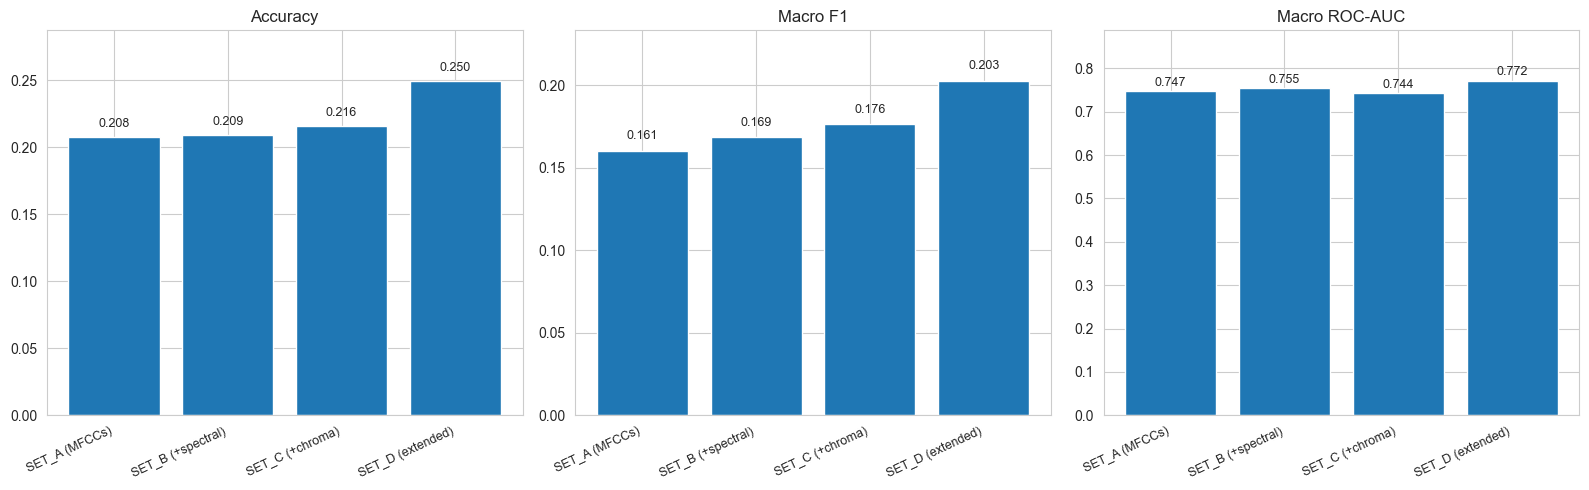

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

names = df_results['name']
x = range(len(names))

for ax, metric, title in zip(axes, ['accuracy', 'macro_f1', 'macro_roc_auc'], 
                               ['Accuracy', 'Macro F1', 'Macro ROC-AUC']):
    bars = ax.bar(x, df_results[metric])
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=25, ha='right', fontsize=9)
    ax.set_title(title)
    ax.set_ylim(0, max(df_results[metric]) * 1.15)
    for bar, val in zip(bars, df_results[metric]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "feature_comparison.png", dpi=150)
plt.show()

## 5. Analysis

Looking at the results:

- **SET_A (MFCCs only)** already gives a decent ROC-AUC of 0.747. MFCCs capture the spectral envelope, which is clearly the most important thing for telling species apart. But using just mean+std might miss how the call changes over time.

- **SET_B (+spectral)** goes up slightly to 0.755. The extra spectral features add some information about frequency range and spread.

- **SET_C (+chroma)** actually dropped a bit to 0.744. So chroma features (which pitch classes are present) didn't help here — they're more of a music thing and animal calls aren't really tonal in that way.

- **SET_D (extended stats)** is clearly the best, with ROC-AUC 0.772 and accuracy jumping to 25%. The min/max/percentile statistics capture temporal variability that mean+std miss. Training time goes from ~7s to ~14s because of the extra features, but that's fine.

| | Best performance | Best trade-off |
|--|-----------------|----------------|
| Feature set | SET_D (extended) | SET_C or SET_D |

I'll use SET_D for the model comparison since it clearly performs best.

In [9]:
# save results for later use
df_results.to_csv(FIG_DIR / "feature_comparison_results.csv", index=False)

best = df_results.loc[df_results['macro_roc_auc'].idxmax()]
print(f"\nBest feature set by ROC-AUC: {best['name']} with ROC-AUC = {best['macro_roc_auc']:.4f}")


Best feature set by ROC-AUC: SET_D (extended) with ROC-AUC = 0.7719
